<div align="center">

<h2><strong>PEMBUATAN RECIPE UNTUK SIMULASI GELOMBANG SEISMIK SINTETIS (SYNTHETIC SEISMIC-WAVE REFERENCE IMPLEMENTATION)</strong></h2>
<h3><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h3>


<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong> Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li>
    <strong>MUHAMMAD IRFAN</strong>
    <div style="margin-top:10px;">
      <strong>H061241002</strong>
    </div>
  </li>
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong></strong></p>
<p><strong></strong></p>
<p><strong>2026</strong></p>

</div>

## **STUDI KASUS**
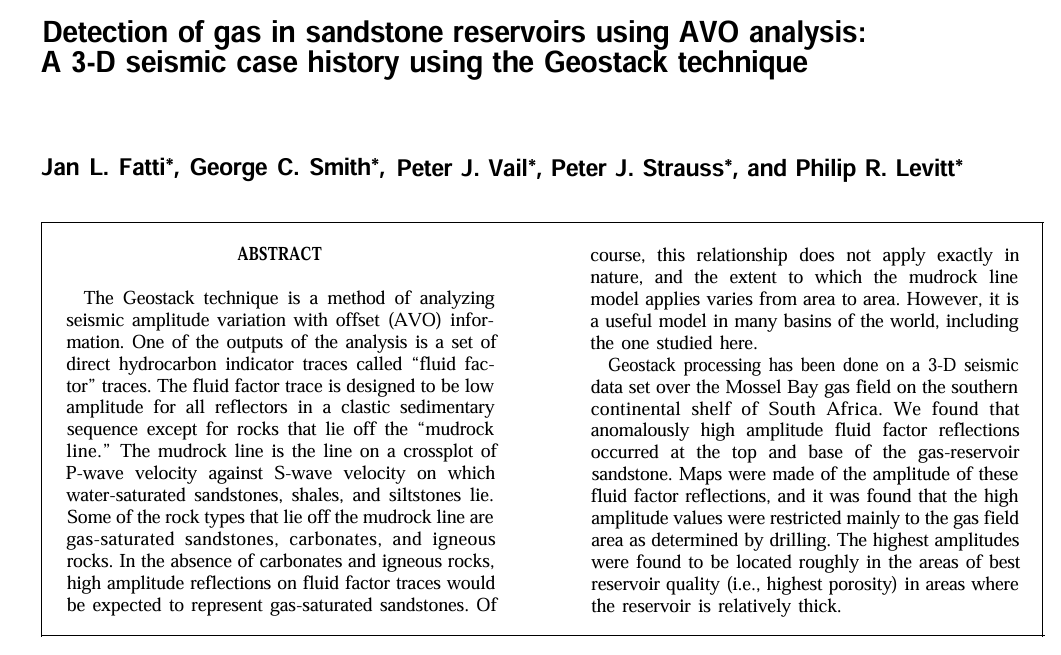

Di lapangan gas Mossel Bay, identifikasi keberadaan hidrokarbon menghadapi kendala utama akibat terhalangnya antarmuka bagian atas reservoar gas (top reservoir masking). Kondisi ini terjadi karena batupasir bersaturasi gas (gas-bearing sandstone) tertutup secara langsung oleh lapisan serpih berkecepatan rendah (low-velocity shale). Kemiripan impedansi akustik yang signifikan antara kedua lapisan tersebut menghasilkan kontras yang sangat kecil, sehingga pantulan seismik biasa (zero-offset P-wave) dari batas atas reservoar (Horizon C) menjadi sangat lemah, samar, atau bahkan tidak tampak sama sekali pada penampang seismik.

Kondisi tersebut berdampak pada sulitnya membedakan Indikator Hidrokarbon Langsung (Direct Hydrocarbon Indicator / DHI) secara akurat. Pada penampang seismik konvensional, respon lonjakan amplitudo tinggi (bright spot) yang teramati sering kali mengecoh karena didominasi oleh pengaruh batuan serpih di atasnya, bukan murni merepresentasikan respon dari reservoar gas itu sendiri. Hambatan ini kian kompleks akibat variasi karakteristik AVO (Amplitude Versus Offset) yang dipengaruhi oleh fluida dan porositas batuan, di mana kehadiran gas menurunkan nilai kecepatan gelombang P ($V_p$) secara tajam sementara kecepatan gelombang S ($V_s$) cenderung konstan. Akibatnya, nilai respon batuan bergeser keluar dari kurva acuan Mudrock Line, yang menuntut penggunaan pendekatan pemodelan khusus seperti analisis Fluid Factor ($\Delta F$) untuk memetakan keberadaan gas secara lebih presisi.

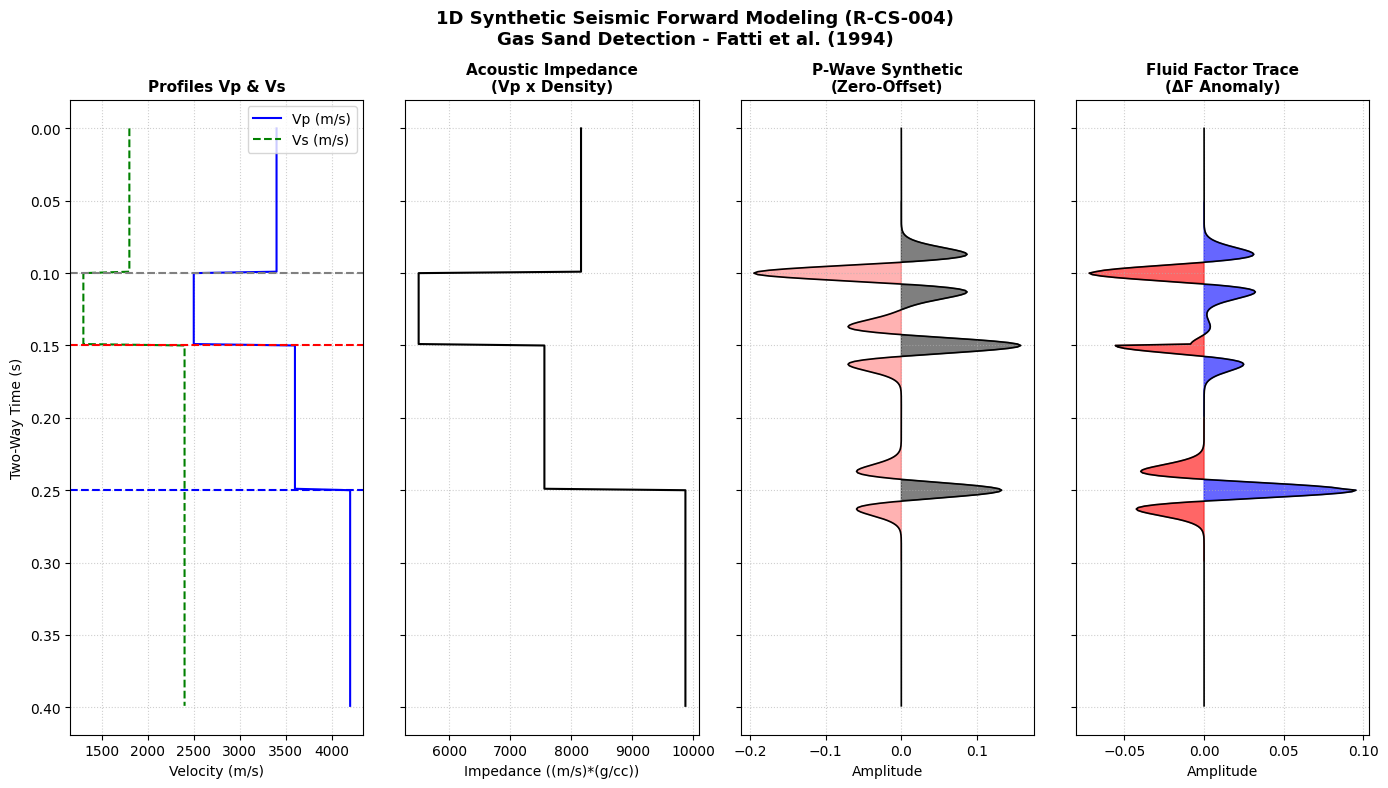

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETER MODEL & KISI (GRID 1D)
# ==========================================
dt = 0.001  # Sampling time (detik)
t_max = 0.4  # Durasi simulasi (detik)
time = np.arange(0, t_max, dt)
nt = len(time)

# ==========================================
# 2. DEFINISI LOG LITHOLOGY & FISIKA BATUAN
# (Berdasarkan Well F-AD1 / F-A10 dari Jurnal)
# ==========================================
# Inisialisasi profil medium
vp = np.zeros(nt)
vs = np.zeros(nt)
rho = np.zeros(nt)

# Batas-batas horizon dalam domain waktu (Two-Way Time)
# Lapisan 1: Shale Atas (0 - 0.10s)
vp[:100] = 3400.0   # Vp (m/s)
vs[:100] = 1800.0   # Vs (m/s)
rho[:100] = 2.40    # Density (g/cc)

# Lapisan 2: Low-Velocity Shale (0.10s - 0.15s)
vp[100:150] = 2500.0
vs[100:150] = 1300.0
rho[100:150] = 2.20

# Lapisan 3: Gas Sandstone / Horizon C (0.15s - 0.25s) -> Dropped Vp
vp[150:250] = 3600.0
vs[150:250] = 2400.0  # Vs tetap tinggi, Vp/Vs turun tajam
rho[150:250] = 2.10   # Porositas tinggi (densitas turun)

# Lapisan 4: Water Sandstone / GWC (0.25s - 0.40s)
vp[250:] = 4200.0
vs[250:] = 2400.0
rho[250:] = 2.35

# ==========================================
# 3. KALKULASI IMPEDANSI & REFLEKTIVITAS (Rp & Rs)
# ==========================================
# Acoustic Impedance (I = Vp * rho) & Shear Impedance (J = Vs * rho)
Ip = vp * rho
Is = vs * rho

# Zero-offset Reflectivity Series (Rp dan Rs)
Rp = np.zeros(nt)
Rs = np.zeros(nt)

for i in range(nt - 1):
    Rp[i] = (Ip[i + 1] - Ip[i]) / (Ip[i + 1] + Ip[i])
    Rs[i] = (Is[i + 1] - Is[i]) / (Is[i + 1] + Is[i])

# ==========================================
# 4. RICKER WAVELET & KONVOLUSI (FORWARD MODELING)
# ==========================================
# Membuat Zero-Phase Ricker Wavelet (Dominant Frequency = 30 Hz)
f_dom = 30.0
t_wav = np.arange(-0.05, 0.05, dt)
wavelet = (1.0 - 2.0 * (np.pi * f_dom * t_wav)**2) * np.exp(-(np.pi * f_dom * t_wav)**2)

# Konvolusi wavelet dengan koefisien refleksi (Synthetic Seismograms)
p_wave_synth = np.convolve(Rp, wavelet, mode='same')
s_wave_synth = np.convolve(Rs, wavelet, mode='same')

# ==========================================
# 5. KALKULASI FLUID FACTOR (dF Trace)
# Formula Fatti et al. (1994): dF = Rp - 1.16 * (Vs/Vp) * Rs
# ==========================================
gain_g = 1.16 * (vs / vp)
fluid_factor_synth = p_wave_synth - (gain_g * s_wave_synth)

# ==========================================
# 6. VISUALISASI HASIL (PLOT PAPER-READY)
# ==========================================
fig, ax = plt.subplots(1, 4, figsize=(14, 8), sharey=True)

# Subplot 1: Profil Kecepatan Vp dan Vs
ax[0].plot(vp, time, 'b-', label='Vp (m/s)', linewidth=1.5)
ax[0].plot(vs, time, 'g--', label='Vs (m/s)', linewidth=1.5)
ax[0].set_title("Profiles Vp & Vs", fontsize=11, fontweight='bold')
ax[0].set_ylabel("Two-Way Time (s)", fontsize=10)
ax[0].set_xlabel("Velocity (m/s)", fontsize=10)
ax[0].legend(loc='upper right')
ax[0].grid(True, linestyle=':', alpha=0.6)
ax[0].invert_yaxis()

# Annotations Horizon
ax[0].axhline(y=0.10, color='gray', linestyle='--')
ax[0].axhline(y=0.15, color='r', linestyle='--', label='Horizon C (Top Gas)')
ax[0].axhline(y=0.25, color='b', linestyle='--', label='GWC (Base Gas)')

# Subplot 2: Acoustic Impedance
ax[1].plot(Ip, time, 'k-', linewidth=1.5)
ax[1].set_title("Acoustic Impedance\n(Vp x Density)", fontsize=11, fontweight='bold')
ax[1].set_xlabel("Impedance ((m/s)*(g/cc))", fontsize=10)
ax[1].grid(True, linestyle=':', alpha=0.6)

# Subplot 3: P-Wave Synthetic Seismogram
ax[2].plot(p_wave_synth, time, 'k-', linewidth=1.2)
ax[2].fill_betweenx(time, 0, p_wave_synth, where=(p_wave_synth > 0), color='black', alpha=0.5)
ax[2].fill_betweenx(time, 0, p_wave_synth, where=(p_wave_synth < 0), color='red', alpha=0.3)
ax[2].set_title("P-Wave Synthetic\n(Zero-Offset)", fontsize=11, fontweight='bold')
ax[2].set_xlabel("Amplitude", fontsize=10)
ax[2].grid(True, linestyle=':', alpha=0.6)

# Subplot 4: Fluid Factor (dF) Trace
ax[3].plot(fluid_factor_synth, time, 'k-', linewidth=1.2)
ax[3].fill_betweenx(time, 0, fluid_factor_synth, where=(fluid_factor_synth > 0), color='blue', alpha=0.6)
ax[3].fill_betweenx(time, 0, fluid_factor_synth, where=(fluid_factor_synth < 0), color='red', alpha=0.6)
ax[3].set_title("Fluid Factor Trace\n(ΔF Anomaly)", fontsize=11, fontweight='bold')
ax[3].set_xlabel("Amplitude", fontsize=10)
ax[3].grid(True, linestyle=':', alpha=0.6)

plt.suptitle("1D Synthetic Seismic Forward Modeling (R-CS-004)\nGas Sand Detection - Fatti et al. (1994)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## **Analisis Hasil Pemodelan Sintetik 1D (R-CS-004) pada Studi Kasus Reservoar Gas**
Pemodelan gelombang seismik sintetik 1D berbasis forward modeling berhasil direalisasikan untuk merepresentasikan respon batuan pada studi kasus deteksi reservoar gas. Pada panel profil kecepatan ($V_p$ dan $V_s$), terlihat penurunan kecepatan gelombang P ($V_p$) yang sangat tajam saat memasuki zona gas-bearing sandstone di rentang waktu $0.15\text{ s}$ hingga $0.25\text{ s}$, sementara kecepatan gelombang S ($V_s$) relatif konstan. Fenomena fisik ini menyebabkan nilai impedansi akustik (Acoustic Impedance) merosot signifikan pada zona reservoar gas.   Dampak dari kontras impedansi tersebut terlihat jelas pada pembandingan dua jejak (trace) seismik sintetik. Pada penampang P-Wave Synthetic (Zero-Offset), refleksi dari bagian atas reservoar gas (Horizon C pada $0.15\text{ s}$) tampak samar dan tertutupi oleh respon amplitudo dari low-velocity shale di atasnya. Sebaliknya, pada penampang Fluid Factor Trace ($\Delta F$ Anomaly), pengaruh perlapisan non-gas tereliminasi sehingga memunculkan anomali trough (warna merah) yang sangat jelas tepat di batas atas Gas Sand serta anomali peak (warna biru) yang kuat di batas kontak air-gas (Gas-Water Contact / GWC pada $0.25\text{ s}$). Hal ini membuktikan bahwa metode Fluid Factor sangat efektif memetakan keberadaan reservoar gas yang tersembunyi.  